In [1]:
%matplotlib qt
import numpy as np
import matplotlib.pyplot as plt
import roboticstoolbox as rtb
from spatialmath import SE3
from workspace import *

In [2]:
L1 = 3
L2 = 2
L3 = 1.5

e1 = rtb.RevoluteMDH(a=0,alpha=0,d=L1,qlim=[-np.pi,np.pi])
e2 = rtb.RevoluteMDH(a=0,alpha=np.radians(90),d=0,qlim=[-np.pi/2,np.pi/2])
e3 = rtb.RevoluteMDH(a=L2,alpha=0,d=0,qlim=[-np.pi/2,np.pi/2])

robot = rtb.DHRobot([e1,e2,e3],name='Antropomorfico')

robot.tool = SE3.Tx(L3)

print(robot)

DHRobot: Antropomorfico, 3 joints (RRR), dynamics, modified DH parameters
┌──────┬───────┬─────┬────┬─────────┬────────┐
│ aⱼ₋₁ │ ⍺ⱼ₋₁  │ θⱼ  │ dⱼ │   q⁻    │   q⁺   │
├──────┼───────┼─────┼────┼─────────┼────────┤
│    0 │  0.0° │  q1 │  3 │ -180.0° │ 180.0° │
│    0 │ 90.0° │  q2 │  0 │  -90.0° │  90.0° │
│    2 │  0.0° │  q3 │  0 │  -90.0° │  90.0° │
└──────┴───────┴─────┴────┴─────────┴────────┘

┌──────┬─────────────────────────────────────┐
│ tool │ t = 1.5, 0, 0; rpy/xyz = 0°, 0°, 0° │
└──────┴─────────────────────────────────────┘



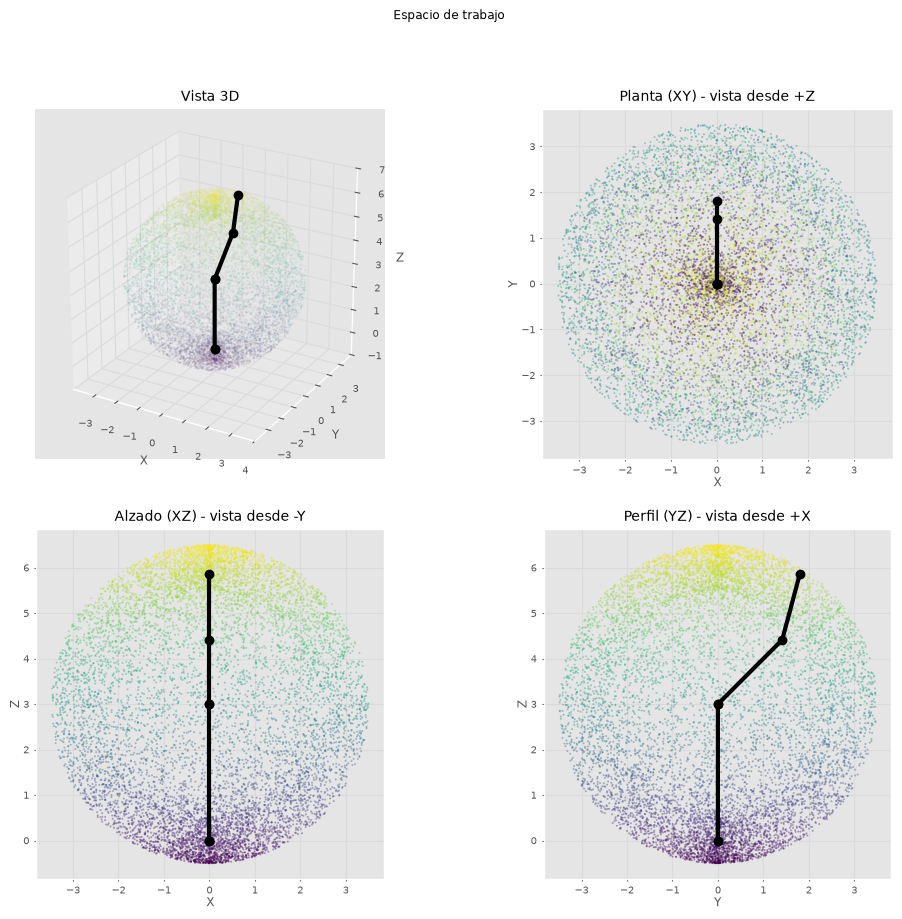

In [3]:
Q,P = espacio_trabajo(robot=robot,N=10000,devolver_q=True)

q = np.deg2rad([90,45,30])

mostrar(P,vista='Todas',robot=robot,q=q)

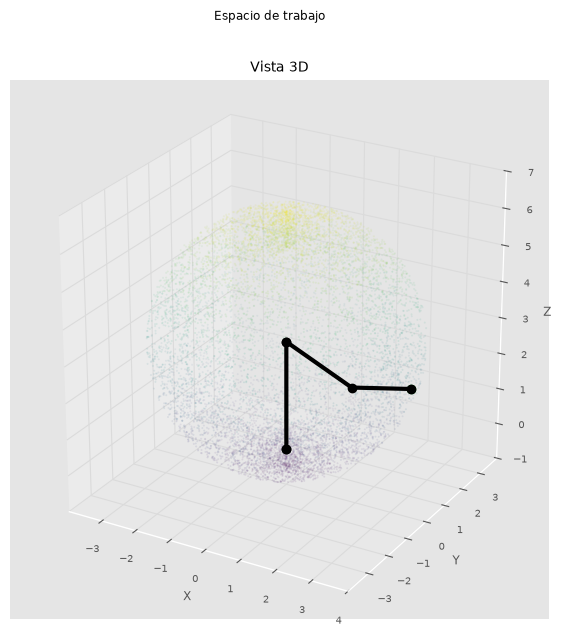

In [4]:
Obj = SE3.Trans(3,1,2)

sol = robot.ikine_LM(Obj,mask=[1,1,1,0,0,0])

mostrar(P,vista='3d',robot=robot,q=sol.q if sol.success else None,puntos=Obj.t,
        colores_puntos='g' if sol.success else 'r')